# Gao et al. 2021 — Breast Cancer · 03 Signatures
Embryonic module signatures (Gast, pSom, Crest) scored with the union control pool, read off the
manifold. **Gate 2**: is the embryonic pattern present? Geography is read from the signature
embeddings and their smoothed spatial correlations.

In [ ]:
import os, sys, glob
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*6)); pth_data = os.path.join(pth,'data')
pth_out = os.path.join(pth_data,'cancer','vertebrate','CCCA','Claude',cat,name)
pth_fig = os.path.join(pth,'figures','cancer','vertebrate','CCCA','Claude',cat,name)
pth_cb  = os.path.join(pth_fig,'colorbars')
os.makedirs(pth_out,exist_ok=True); os.makedirs(pth_cb,exist_ok=True)

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out,'manifold.h5ad'))
pth_feat = os.path.join(pth_data,'features','biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.dropna().drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
print('cells:', adata.shape[0])

Gast: 79/81 genes present
pSom: 94/98 genes present
Crest: 103/104 genes present
cells: 6605


## Gate 2 readout — module geography
Raw module means give the honest global strength; smoothed spatial correlations give the
geography. **Gast and pSom co-vary in opposite directions (organized cross-repression)** and
**Crest is an inverse/terminal gradient** — the embryonic axis is present but collapsed onto a
single continuous trajectory (no divergent arms). Per the task definition (non-branching case,
organized cross-repression with a terminal Crest gradient counts as non-branching), this
**passes Gate 2 (GO)** with **Gate 3 NA**.

In [ ]:
print('raw module means (global strength):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[s]); print(f'  {s}: rho = {rho:+.3f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'Neural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')
# Crest arm-enrichment flag: does Crest peak with Gast or pSom?
print(f"Crest-arm flag: Crest_sm~Gast_sm r={np.corrcoef(adata.obs['Crest_sm'],adata.obs['Gast_sm'])[0,1]:+.2f}, "
      f"Crest_sm~pSom_sm r={np.corrcoef(adata.obs['Crest_sm'],adata.obs['pSom_sm'])[0,1]:+.2f}")
print('GATE 2: organized Gast<->pSom cross-repression + terminal inverse Crest gradient -> GO (non-branching)')
print('GATE 3: no bifurcation -> NA')

raw module means (global strength): {'Gast': -0.0247, 'pSom': 0.0204, 'Crest': -0.0446}
smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.50
  Crest_sm vs Gast_sm: r = +0.19
  Crest_sm vs pSom_sm: r = -0.55
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.325
  pSom_sm: rho = +0.016
  Crest_sm: rho = +0.236
Neural-crest-high decile mean pseudotime = 0.77 (terminal if ~1)
Crest-arm flag: Crest_sm~Gast_sm r=+0.19, Crest_sm~pSom_sm r=-0.55
GATE 2: organized Gast<->pSom cross-repression + terminal inverse Crest gradient -> GO (non-branching)
GATE 3: no bifurcation -> NA


## Signature figures (raw scores, house (3.5,1.5) layout) + colorbars

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


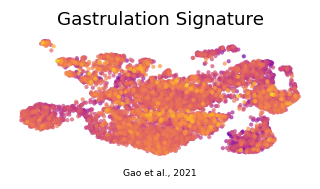

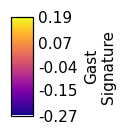

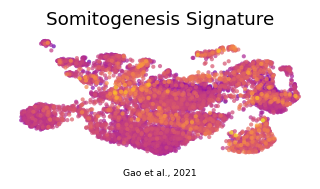

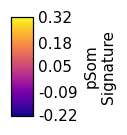

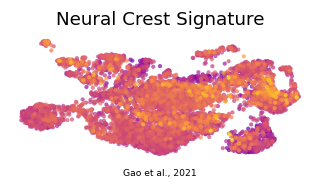

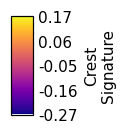

In [ ]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Gao et al., 2021', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi_ = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi_, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')
    plt.show()

In [ ]:
adata.write(os.path.join(pth_out,'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (6605, 18227)
